# 02 - Training, Evaluasi, dan Analisis Kesalahan

Notebook ini melatih lima model untuk membedakan komentar **normal (0)** dan **promosi judi (1)**.

**Alur:** dataset clean -> *(opsional: stemming / lemmatization)* -> split 80/20 -> seimbangkan data latih ->
vektorisasi TF-IDF *(atau FastText)* -> training 5 model -> evaluasi -> analisis kesalahan -> simpan

| | |
|---|---|
| **Cara menjalankan** | `Run All`. Pengaturan bawaan melewati semua langkah opsional |
| **Input** | `data/dataset_clean.csv` (hasil notebook 01) |
| **Output model** | vectorizer, 5 file model `.joblib`, dan `konfigurasi.json` di folder `models/` |
| **Untuk laporan** | Tabel 2.1 - 2.13 dan Gambar 2.1 - 2.4; file tersimpan di `outputs/` |

## 1. Pengaturan langkah opsional

Ubah pilihan di sel berikut, lalu `Run All`. Jika nilainya `None` atau `False`, langkah tersebut **dilewati (bypass)** dan
library tambahannya tidak dipasang.

| Pengaturan | Pilihan | Arti | Contoh |
|---|---|---|---|
| `NORMALISASI_KATA` | `None` | tidak mengubah bentuk kata | `permainan` tetap `permainan` |
| | `"stemming"` | memotong imbuhan dengan Sastrawi | `keberuntungan` -> `untung` |
| | `"lemmatization"` | mencari bentuk dasar lewat kamus (simplemma) | `permainan` -> `main` |
| `FITUR` | `"tfidf"` | bobot kata, tanpa memperhatikan makna | |
| | `"fasttext"` | embedding: kata dengan konteks mirip memiliki vektor yang mirip | `gacor` dekat dengan `slot` |
| `PAKAI_LANGKAH_TAMBAHAN` | `False` / `True` | menjalankan fungsi `langkah_tambahan` buatan sendiri (bagian 2) | |

FastText di sini **dilatih dari data latih sendiri** supaya ringan. Model siap pakai dari fastText berukuran beberapa GB.

Setiap kali notebook dijalankan, model di `models/` diganti dan pilihan ini dicatat di `models/konfigurasi.json`. Notebook 03
membacanya secara otomatis, jadi pengolahan teksnya tetap sama. Hasil tiap percobaan dikumpulkan di Tabel 2.6.

In [1]:
NORMALISASI_KATA = None            # None, "stemming", atau "lemmatization"
FITUR = "tfidf"                    # "tfidf" atau "fasttext"
PAKAI_LANGKAH_TAMBAHAN = False     # True untuk menjalankan fungsi langkah_tambahan

assert NORMALISASI_KATA in (None, "stemming", "lemmatization"), "Pilihan NORMALISASI_KATA tidak dikenal"
assert FITUR in ("tfidf", "fasttext"), "Pilihan FITUR tidak dikenal"

## 2. Setup

In [2]:
%pip install -q pandas numpy scikit-learn jinja2 matplotlib joblib

# Library opsional hanya dipasang jika dipilih
if NORMALISASI_KATA == "stemming":
    %pip install -q Sastrawi
if NORMALISASI_KATA == "lemmatization":
    %pip install -q simplemma
if FITUR == "fasttext":
    %pip install -q gensim

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import os
import re
from functools import lru_cache

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.utils import resample

RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
pd.set_option("display.max_colwidth", 90)

WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})


def tampil(tabel, judul, file=None, sembunyikan_index=False):
    """Menampilkan tabel yang rapi untuk di-screenshot. Jika file diisi, tabel juga disimpan ke outputs/."""
    if file:
        tabel.to_csv(f"outputs/{file}", index=not sembunyikan_index)
    gaya = (tabel.style.set_caption(judul).format(precision=4, na_rep="-")
            .set_properties(**{"text-align": "left", "white-space": "normal"})
            .set_table_styles([
                {"selector": "caption", "props": "caption-side: top; font-weight: bold; font-size: 1.05em; "
                                                 "text-align: left; padding-bottom: 6px; color: inherit;"},
                {"selector": "th", "props": "text-align: left;"},
            ]))
    display(gaya.hide(axis="index") if sembunyikan_index else gaya)

Sel berikut berisi fungsi langkah opsional. **Di sinilah** langkah baru dapat ditambahkan, yaitu pada `langkah_tambahan`.

In [4]:
def siapkan_pengubah_kata(metode):
    if metode == "stemming":
        from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
        return StemmerFactory().create_stemmer().stem
    if metode == "lemmatization":
        import simplemma
        return lambda kata: simplemma.lemmatize(kata, lang="id")
    return None                                              # None = langkah ini dilewati


pengubah_kata = siapkan_pengubah_kata(NORMALISASI_KATA)
POLA_KATA_BIASA = re.compile(r"[a-z]+(-[a-z]+)*")


@lru_cache(maxsize=None)                                     # kata yang sama cukup diproses sekali
def ubah_kata(kata):
    return pengubah_kata(kata)


def langkah_tambahan(teks):
    # TEMPAT MENAMBAHKAN LANGKAH LAIN. Aktifkan dengan PAKAI_LANGKAH_TAMBAHAN = True.
    # Jika fungsi ini diubah, salin perubahan yang sama ke notebook 02 dan 03.
    # Contoh: menyamakan kata tidak baku -> return teks.replace("gk", "gak")
    return teks


def siapkan_teks(teks):
    if pengubah_kata:
        # Hanya kata biasa yang diubah, sehingga nama situs seperti alexis17 tetap utuh
        teks = " ".join(ubah_kata(k) if POLA_KATA_BIASA.fullmatch(k) else k for k in teks.split())
    if PAKAI_LANGKAH_TAMBAHAN:
        teks = langkah_tambahan(teks)
    return teks

## 3. Memuat dataset

Dua kolom utama yang dipakai adalah `komentar_clean` sebagai input dan `label` sebagai target. Langkah opsional disimpan di
kolom baru, `teks_model`. Jika semua langkah opsional dilewati, isinya sama dengan `komentar_clean`.

In [5]:
df = pd.read_csv("data/dataset_clean.csv")
df["teks_model"] = df["komentar_clean"].apply(siapkan_teks)

if NORMALISASI_KATA or PAKAI_LANGKAH_TAMBAHAN:
    berubah = df.loc[df["teks_model"] != df["komentar_clean"], ["komentar_clean", "teks_model"]]
    print(f"Teks yang berubah oleh langkah opsional: {len(berubah):,} dari {len(df):,}")
    tampil(berubah.head(8), "Tabel 2.0. Contoh hasil langkah opsional", sembunyikan_index=True)

    # Setelah kata diubah, dua komentar bisa menjadi sama: buang lagi konflik label dan duplikatnya
    df = df[df.groupby("teks_model")["label"].transform("nunique") == 1].drop_duplicates("teks_model")
else:
    print("Langkah opsional dilewati: teks_model sama dengan komentar_clean")

X, y = df["teks_model"], df["label"]
print(f"Jumlah data: {len(df):,} baris")
tampil(y.value_counts().rename(index=NAMA_LABEL).rename_axis("Label").to_frame("Jumlah"), "Tabel 2.1. Distribusi label dataset clean")

Langkah opsional dilewati: teks_model sama dengan komentar_clean
Jumlah data: 8,270 baris


,Jumlah
Label,
Normal (0),5720
Promosi judi (1),2550


## 4. Pembagian data dan penyeimbangan

- Data dibagi **80% latih dan 20% uji** secara *stratified*, sehingga proporsi kelas di kedua bagian sama. Data uji baru
  dipakai saat evaluasi akhir.
- Komentar normal jauh lebih banyak daripada promosi. Agar model tidak condong ke kelas mayoritas, komentar normal di data
  latih dikurangi secara acak (*undersampling*) hingga jumlahnya sama dengan komentar promosi.
- Undersampling **hanya untuk data latih**. Data uji dibiarkan apa adanya agar tetap mencerminkan kondisi sebenarnya.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

latih = pd.DataFrame({"teks": X_train, "label": y_train})
promosi = latih[latih["label"] == 1]
normal = resample(latih[latih["label"] == 0], replace=False, n_samples=len(promosi), random_state=RANDOM_STATE)
latih = pd.concat([normal, promosi]).sample(frac=1, random_state=RANDOM_STATE)
X_train_seimbang, y_train_seimbang = latih["teks"], latih["label"]

pembagian = pd.DataFrame({"Latih (sebelum undersampling)": y_train.value_counts(),
                          "Latih (sesudah undersampling)": y_train_seimbang.value_counts(),
                          "Uji": y_test.value_counts()}).rename(index=NAMA_LABEL)
pembagian.loc["Total"] = pembagian.sum()
tampil(pembagian.rename_axis("Label"), "Tabel 2.2. Pembagian data", "pembagian_data.csv")

,Latih (sebelum undersampling),Latih (sesudah undersampling),Uji
Label,,,
Normal (0),4576,2040,1144
Promosi judi (1),2040,2040,510
Total,6616,4080,1654


## 5. Vektorisasi

Model hanya bisa membaca angka, sehingga setiap komentar harus diubah menjadi vektor.

- **TF-IDF (bawaan):** bobot sebuah kata tinggi jika kata itu sering muncul di komentar tersebut tetapi jarang muncul di
  komentar lain. Hanya **5.000 kata** teratas yang dipakai.
- **FastText (opsional):** setiap kata menjadi vektor 100 dimensi, lalu vektor komentar adalah rata-rata vektor katanya.

Vectorizer dipelajari **dari data latih saja**, supaya isi data uji tidak bocor ke proses training.

In [7]:
def ubah_ke_vektor(daftar_teks, vektorizer, fitur):
    if fitur == "tfidf":
        return vektorizer.transform(daftar_teks)

    # FastText: vektor satu komentar = rata-rata vektor kata di dalamnya
    def vektor_komentar(teks):
        kata = teks.split()
        if not kata:
            return np.zeros(vektorizer.vector_size)
        return np.mean([vektorizer.wv[k] for k in kata], axis=0)

    return np.vstack([vektor_komentar(t) for t in daftar_teks])

In [8]:
if FITUR == "tfidf":
    vektorizer = TfidfVectorizer(max_features=5000).fit(X_train_seimbang)
else:
    from gensim.models import FastText
    vektorizer = FastText(sentences=[t.split() for t in X_train_seimbang], vector_size=100, window=5, min_count=2,
                          epochs=10, seed=RANDOM_STATE, workers=1)

X_train_vec = ubah_ke_vektor(X_train_seimbang, vektorizer, FITUR)
X_test_vec = ubah_ke_vektor(X_test, vektorizer, FITUR)
print(f"Metode: {FITUR}")
print(f"Bentuk data latih: {X_train_vec.shape} (komentar, fitur)")
print(f"Bentuk data uji  : {X_test_vec.shape}")

Metode: tfidf
Bentuk data latih: (4080, 5000) (komentar, fitur)
Bentuk data uji  : (1654, 5000)


In [9]:
if FITUR == "tfidf":
    # Contoh: bobot kata pada komentar pertama yang berisi minimal 5 kata dalam kosakata
    i = next(i for i in range(X_train_vec.shape[0]) if X_train_vec[i].nnz >= 5)
    bobot = pd.Series(X_train_vec[i].toarray().ravel(), index=vektorizer.get_feature_names_out())
    bobot = bobot[bobot > 0].sort_values(ascending=False).round(3).rename_axis("Kata").to_frame("Bobot TF-IDF")
    tampil(bobot, f"Tabel 2.3. Contoh TF-IDF pada komentar: {X_train_seimbang.iloc[i]}")
else:
    kata_contoh = "gacor" if "gacor" in vektorizer.wv else vektorizer.wv.index_to_key[0]
    mirip = pd.DataFrame(vektorizer.wv.most_similar(kata_contoh, topn=8), columns=["Kata", "Kemiripan"])
    tampil(mirip, f"Tabel 2.3. Kata yang paling mirip dengan '{kata_contoh}' menurut FastText", sembunyikan_index=True)

,Bobot TF-IDF
Kata,
bonanja,0.4740
swert,0.4740
pol,0.4480
puas,0.4120
gacir,0.3480
banget,0.2450


## 6. Training

| Model | Cara kerja singkat |
|---|---|
| Naive Bayes | menghitung peluang kelas berdasarkan frekuensi kata (`MultinomialNB`; `GaussianNB` untuk FastText karena vektornya bisa bernilai negatif) |
| SVM | mencari batas pemisah terbaik antara dua kelas |
| Random Forest | gabungan banyak pohon keputusan; parameternya dicari dengan `GridSearchCV` pada data latih |
| KNN | melihat komentar paling mirip di data latih |
| Logistic Regression | memberi bobot pada setiap fitur, lalu menghitung peluang |

In [10]:
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"n_estimators": [100, 200], "max_depth": [10, None], "min_samples_split": [2, 5]},
    cv=3, scoring="f1",
)

MODEL = {
    "naive_bayes": MultinomialNB() if FITUR == "tfidf" else GaussianNB(),
    "svm": SVC(random_state=RANDOM_STATE),
    "random_forest": grid_rf,
    "knn": KNeighborsClassifier(),
    "logistic_regression": LogisticRegression(max_iter=1000),
}

for nama, model in MODEL.items():
    model.fit(X_train_vec, y_train_seimbang)
    print(f"Selesai: {nama}")

MODEL["random_forest"] = grid_rf.best_estimator_
print("\nParameter terbaik Random Forest:", grid_rf.best_params_)

Selesai: naive_bayes


Selesai: svm


Selesai: random_forest
Selesai: knn
Selesai: logistic_regression

Parameter terbaik Random Forest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


## 7. Evaluasi pada data uji

| Metrik | Arti |
|---|---|
| Accuracy | proporsi semua prediksi yang benar |
| Precision | dari komentar yang ditandai promosi, berapa yang benar promosi |
| Recall | dari semua komentar promosi, berapa yang berhasil ditemukan |
| F1 | rata-rata harmonik precision dan recall |
| ROC-AUC | kemampuan model mengurutkan promosi di atas normal |

Karena data uji tidak seimbang, **F1** lebih bisa diandalkan daripada accuracy. Precision, recall, dan F1 dihitung untuk
kelas promosi judi. Pada tabel, `tp` = promosi tertangkap, `tn` = normal benar, `fp` = normal yang salah ditandai promosi,
dan `fn` = promosi yang lolos.

In [11]:
def skor_promosi(model, X):
    """Semakin tinggi semakin condong ke promosi: peluang kelas 1, atau jarak ke batas pemisah untuk SVM."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


baris, prediksi, skor = {}, {}, {}
for nama, model in MODEL.items():
    prediksi[nama] = model.predict(X_test_vec)
    skor[nama] = skor_promosi(model, X_test_vec)
    tn, fp, fn, tp = confusion_matrix(y_test, prediksi[nama]).ravel()
    baris[nama] = {
        "accuracy": accuracy_score(y_test, prediksi[nama]),
        "precision": precision_score(y_test, prediksi[nama]),
        "recall": recall_score(y_test, prediksi[nama]),
        "f1": f1_score(y_test, prediksi[nama]),
        "roc_auc": roc_auc_score(y_test, skor[nama]),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }

metrik = pd.DataFrame(baris).T
metrik[["tn", "fp", "fn", "tp"]] = metrik[["tn", "fp", "fn", "tp"]].astype(int)
metrik = metrik.sort_values("f1", ascending=False).rename_axis("model")
MODEL_TERBAIK = metrik.index[0]
tampil(metrik, "Tabel 2.4. Hasil evaluasi pada data uji (urut dari F1 tertinggi)", "metrik_evaluasi.csv")

,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
model,,,,,,,,,
svm,0.9692,0.9456,0.9549,0.9502,0.9948,1116,28,23,487
logistic_regression,0.9607,0.9371,0.9353,0.9362,0.9913,1112,32,33,477
random_forest,0.9480,0.8941,0.9431,0.9179,0.9889,1087,57,29,481
naive_bayes,0.9208,0.8003,0.9902,0.8852,0.9916,1018,126,5,505
knn,0.7969,0.8919,0.3882,0.5410,0.8343,1120,24,312,198


In [12]:
laporan = pd.DataFrame(classification_report(y_test, prediksi[MODEL_TERBAIK], target_names=["Normal", "Promosi judi"],
                                             output_dict=True)).T
laporan.loc["accuracy", ["precision", "recall"]] = np.nan
laporan["support"] = laporan["support"].astype(int)
laporan.loc["accuracy", "support"] = len(y_test)
tampil(laporan.rename_axis("Kelas"), f"Tabel 2.5. Laporan klasifikasi model terbaik: {MODEL_TERBAIK}")

,precision,recall,f1-score,support
Kelas,,,,
Normal,0.9798,0.9755,0.9777,1144
Promosi judi,0.9456,0.9549,0.9502,510
accuracy,-,-,0.9692,1654
macro avg,0.9627,0.9652,0.9640,1654
weighted avg,0.9693,0.9692,0.9692,1654


### Riwayat percobaan

Setiap kombinasi pengaturan dicatat di `outputs/riwayat_eksperimen.csv`, sehingga hasilnya bisa dibandingkan setelah
pengaturan diubah. Kombinasi yang dijalankan ulang akan menggantikan barisnya yang lama.

**Catatan:** memilih pengaturan berdasarkan data uji membuat nilai pengaturan terpilih sedikit lebih tinggi daripada performa
sebenarnya. Selisih kecil sebaiknya tidak dianggap sebagai perbedaan yang pasti.

In [13]:
nama_eksperimen = " + ".join([NORMALISASI_KATA or "tanpa normalisasi", FITUR] + (["langkah tambahan"] if PAKAI_LANGKAH_TAMBAHAN else []))
FILE_RIWAYAT = "outputs/riwayat_eksperimen.csv"

baru = metrik[["accuracy", "precision", "recall", "f1", "roc_auc"]].astype(float).reset_index()
baru.insert(0, "eksperimen", nama_eksperimen)
if os.path.exists(FILE_RIWAYAT):
    lama = pd.read_csv(FILE_RIWAYAT)
    baru = pd.concat([lama[lama["eksperimen"] != nama_eksperimen], baru], ignore_index=True)
baru.to_csv(FILE_RIWAYAT, index=False)

tabel_f1 = baru.pivot(index="eksperimen", columns="model", values="f1")[list(MODEL)]
tabel_f1["F1 tertinggi"] = tabel_f1.max(axis=1)
tampil(tabel_f1.sort_values("F1 tertinggi", ascending=False), "Tabel 2.6. Perbandingan F1 antar percobaan")

model,naive_bayes,svm,random_forest,knn,logistic_regression,F1 tertinggi
eksperimen,,,,,,
tanpa normalisasi + tfidf,0.8852,0.9502,0.9179,0.5410,0.9362,0.9502
stemming + tfidf,0.8731,0.9430,0.9070,0.8610,0.9234,0.9430
lemmatization + tfidf,0.8684,0.9414,0.9043,0.8000,0.9163,0.9414
tanpa normalisasi + fasttext,0.5941,0.6102,0.7566,0.6661,0.6243,0.7566
stemming + fasttext,0.5870,0.6027,0.7517,0.6703,0.6317,0.7517
lemmatization + fasttext,0.5804,0.6011,0.7256,0.6442,0.6278,0.7256


### Grafik evaluasi

**Gambar 2.1. Perbandingan metrik per model**

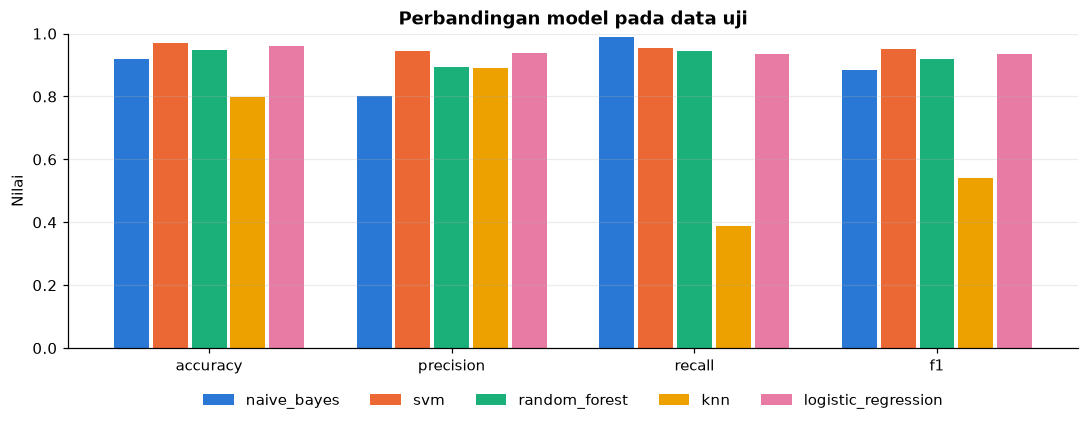

In [14]:
NAMA = list(MODEL)
METRIK = ["accuracy", "precision", "recall", "f1"]

fig, ax = plt.subplots(figsize=(10, 4))
lebar = 0.8 / len(NAMA)
for i, nama in enumerate(NAMA):
    posisi = np.arange(len(METRIK)) - 0.4 + (i + 0.5) * lebar
    ax.bar(posisi, metrik.loc[nama, METRIK].astype(float), width=lebar * 0.9, color=WARNA_MODEL[i], label=nama)
ax.set_xticks(np.arange(len(METRIK)), METRIK)
ax.set_ylim(0, 1)
ax.set(title="Perbandingan model pada data uji", ylabel="Nilai")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=len(NAMA), loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.savefig("outputs/perbandingan_metrik.png", bbox_inches="tight")
plt.show()

**Gambar 2.2. Confusion matrix per model**

Baris adalah label sebenarnya dan kolom adalah prediksi model.

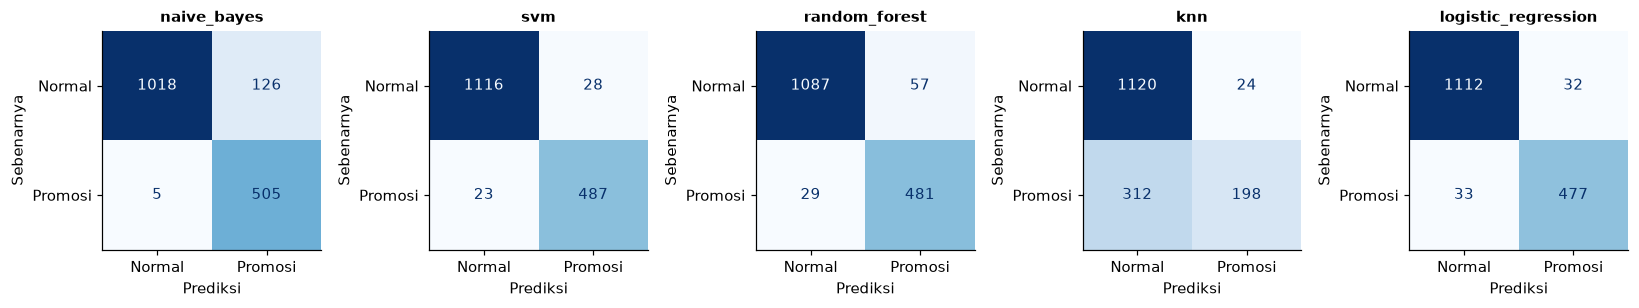

In [15]:
fig, axes = plt.subplots(1, len(NAMA), figsize=(15, 3.2))
for ax, nama in zip(axes, NAMA):
    ConfusionMatrixDisplay(confusion_matrix(y_test, prediksi[nama]), display_labels=["Normal", "Promosi"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nama, fontsize=10)
    ax.grid(False)
    ax.set(xlabel="Prediksi", ylabel="Sebenarnya")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", bbox_inches="tight")
plt.show()

**Gambar 2.3. Kurva ROC.** Semakin dekat kurva ke sudut kiri atas, semakin baik modelnya.

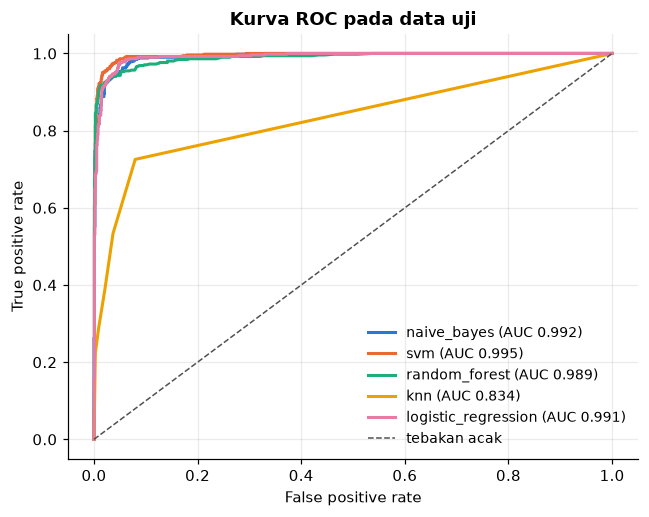

In [16]:
fig, ax = plt.subplots(figsize=(6, 4.8))
for i, nama in enumerate(NAMA):
    fpr, tpr, _ = roc_curve(y_test, skor[nama])
    ax.plot(fpr, tpr, linewidth=2, color=WARNA_MODEL[i], label=f"{nama} (AUC {metrik.loc[nama, 'roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#52514e", label="tebakan acak")
ax.set(title="Kurva ROC pada data uji", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/roc_curve.png", bbox_inches="tight")
plt.show()

## 8. Analisis kesalahan

Nilai evaluasi hanya menunjukkan **berapa banyak** model salah. Bagian ini melihat **komentar mana** yang salah dan **apa
ciri-cirinya**.

| Jenis kesalahan | Arti | Dampak |
|---|---|---|
| **False positive (FP)** | komentar normal ditandai promosi | komentar biasa terkena tuduhan keliru |
| **False negative (FN)** | komentar promosi dianggap normal | promosi judi lolos dari deteksi |

**Gambar 2.4. Jumlah kesalahan per model**

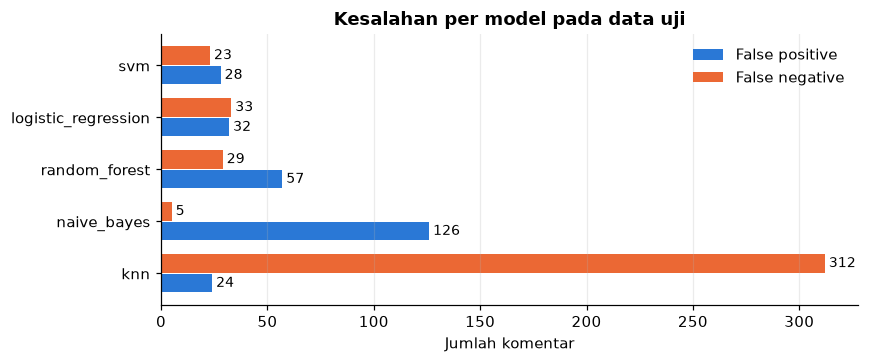

,fp,fn,total,persen_salah
model,,,,
svm,28,23,51,3.0800
logistic_regression,32,33,65,3.9300
random_forest,57,29,86,5.2000
naive_bayes,126,5,131,7.9200
knn,24,312,336,20.3100


In [17]:
kesalahan = metrik[["fp", "fn"]].copy()
kesalahan["total"] = kesalahan["fp"] + kesalahan["fn"]
kesalahan["persen_salah"] = (kesalahan["total"] / len(y_test) * 100).round(2)
kesalahan = kesalahan.sort_values("total")

fig, ax = plt.subplots(figsize=(8, 3.4))
tinggi = 0.38
posisi = np.arange(len(kesalahan))
for geser, kolom, warna, nama_seri in [(tinggi / 2, "fp", WARNA_MODEL[0], "False positive"),
                                       (-tinggi / 2, "fn", WARNA_MODEL[1], "False negative")]:
    ax.barh(posisi + geser, kesalahan[kolom], height=tinggi * 0.92, color=warna, label=nama_seri)
    for y_pos, nilai in zip(posisi + geser, kesalahan[kolom]):
        ax.text(nilai, y_pos, f" {nilai}", va="center", fontsize=9)
ax.set_yticks(posisi, kesalahan.index)
ax.invert_yaxis()
ax.set(title="Kesalahan per model pada data uji", xlabel="Jumlah komentar")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("outputs/kesalahan_per_model.png", bbox_inches="tight")
plt.show()

tampil(kesalahan.rename_axis("model"), f"Tabel 2.7. Jumlah kesalahan per model (dari {len(y_test):,} komentar uji)")

### Contoh kesalahan model terbaik

Komentar diurutkan dari yang **paling yakin tetapi salah**. Kolom `skor` menunjukkan kecondongan model ke promosi: semakin
tinggi semakin condong ke promosi. Skor Naive Bayes, Random Forest, KNN, dan Logistic Regression adalah peluang (0 - 1).
Skor SVM adalah jarak ke batas pemisah, dengan 0 sebagai batasnya.

Periksa juga labelnya: komentar yang tampak benar diprediksi bisa jadi menandakan **label dataset yang keliru**.

In [18]:
uji = df.loc[X_test.index, ["komentar", "komentar_clean", "teks_model", "label"]].copy()
for nama in NAMA:
    uji[f"pred_{nama}"] = prediksi[nama]
uji["skor"] = skor[MODEL_TERBAIK]
uji["prediksi"] = prediksi[MODEL_TERBAIK]
uji["jenis"] = np.select(
    [(uji["label"] == 1) & (uji["prediksi"] == 1), (uji["label"] == 0) & (uji["prediksi"] == 0),
     (uji["label"] == 0) & (uji["prediksi"] == 1)], ["TP (promosi benar)", "TN (normal benar)", "FP (normal -> promosi)"],
    default="FN (promosi lolos)")

KOLOM_CONTOH = ["komentar", "komentar_clean", "skor"]
contoh_fp = uji[uji["jenis"].str.startswith("FP")].sort_values("skor", ascending=False)
contoh_fn = uji[uji["jenis"].str.startswith("FN")].sort_values("skor")

tampil(contoh_fp[KOLOM_CONTOH].head(10), f"Tabel 2.8. Contoh false positive model {MODEL_TERBAIK}: komentar normal yang ditandai promosi", sembunyikan_index=True)
tampil(contoh_fn[KOLOM_CONTOH].head(10), f"Tabel 2.9. Contoh false negative model {MODEL_TERBAIK}: komentar promosi yang lolos", sembunyikan_index=True)

pd.concat([contoh_fp, contoh_fn])[["jenis", "komentar", "komentar_clean", "label", "prediksi", "skor"]].to_csv(
    "outputs/kesalahan_model_terbaik.csv", index=False)

komentar,komentar_clean,skor
"Sepakat, auto menang😁","sepakat , auto menang",1.6597
Perlu dinominasikan sebagai pendongeng terbaik,dinominasikan pendongeng terbaik,0.8362
ngurusnya gampang ? ? ? naaaahhhh silakan .... opini2,ngurusnya gampang ? ? ? naaaahhhh silakan .... opini2,0.6960
mamang bener,mamang bener,0.5017
Salam dari jwaselatan,salam jwaselatan,0.4739
"trending sih inii , gua","trending sih inii , gua",0.3674
Bisa kalah atau bisa menang?,kalah menang ?,0.3089
asyik banget,asyik banget,0.2908
gercep banget,gercep banget,0.2572
modal bansos & hidup mulyono,modal bansos & hidup mulyono,0.2465


komentar,komentar_clean,skor
alhamdulillah aku kena dough В𝒪Ꮤ𝒪𝟩𝟩 250k bobol,alhamdulillah kena dough в𝒪ꮤ𝒪𝟩𝟩 250k bobol,-0.6438
Ya allah semoga yang komentar promosi dora77 di panggil oleh mu secepat . Amin,ya allah semoga komentar promosi dora77 panggil mu secepat . amin,-0.5656
░M𝑨 N 𝑼 𝑻88░ selalu jadi alternatif yang pas untuk menghidupi keluargaku,░m𝑨 n 𝑼 𝑻88░ alternatif pas menghidupi keluargaku,-0.5295
"2:12 bedehhh body nya gaada lawan, semoga BERKAH 99 terus ya ka channel nya","2:12 bedehhh body nya gaada lawan , semoga berkah 99 ya ka channel nya",-0.5183
top mantap is the best bang rifatq,top mantap is the best bang rifatq,-0.2555
suka strada old,suka strada old,-0.2499
"ngeri , sepupu gue smp aja tau p͟͟u͟͟l͟͟a͟͟u͟͟w͟͟i͟͟n͟͟ .","ngeri , sepupu gue smp aja tau p͟͟u͟͟l͟͟a͟͟u͟͟w͟͟i͟͟n͟͟ .",-0.2495
𝕄𝘼 𝑵 𝐔 𝑻 8 8...Gachoor parah geeeeess,𝕄𝘼 𝑵 𝐔 𝑻 8 8 ... gachoor parah geeeeess,-0.2231
explore pulau papua ..,explore pulau papua ..,-0.2218
dah ah tobat gk maengaruda-hoki lg abis maxwin,dah ah tobat gk maengaruda-hoki lg abis maxwin,-0.1742


### Ciri-ciri komentar yang salah

Tabel berikut membandingkan komentar yang benar dan salah diprediksi. Jika persentase **kata di luar kosakata** atau
**karakter non-ASCII** pada FN jauh lebih tinggi daripada TP, model cenderung gagal pada kata yang belum pernah dipelajari
atau nama situs yang disamarkan dengan huruf bergaya.

In [19]:
kosakata = set(vektorizer.get_feature_names_out()) if FITUR == "tfidf" else set(vektorizer.wv.key_to_index)


def persen_di_luar_kosakata(teks):
    kata = re.findall(r"\b\w\w+\b", teks)
    return 100 * sum(k not in kosakata for k in kata) / len(kata) if kata else 0.0


uji["jumlah_kata"] = uji["teks_model"].str.split().str.len()
uji["di_luar_kosakata"] = uji["teks_model"].apply(persen_di_luar_kosakata)
uji["ada_non_ascii"] = uji["teks_model"].str.contains(r"[^\x00-\x7F]", regex=True)

ciri = uji.groupby("jenis").agg(
    **{"Jumlah komentar": ("label", "size"),
       "Rata-rata jumlah kata": ("jumlah_kata", "mean"),
       "Rata-rata kata di luar kosakata (%)": ("di_luar_kosakata", "mean"),
       "Berisi karakter non-ASCII (%)": ("ada_non_ascii", lambda s: 100 * s.mean())}).round(1)
tampil(ciri.rename_axis("Jenis prediksi"), f"Tabel 2.10. Ciri-ciri komentar menurut hasil prediksi model {MODEL_TERBAIK}", "ciri_kesalahan.csv")

,Jumlah komentar,Rata-rata jumlah kata,Rata-rata kata di luar kosakata (%),Berisi karakter non-ASCII (%)
Jenis prediksi,,,,
FN (promosi lolos),23,7.7000,28.3000,47.8000
FP (normal -> promosi),28,4.1000,32.6000,10.7000
TN (normal benar),1116,5.4000,26.3000,5.2000
TP (promosi benar),487,7.5000,7.5000,58.7000


### Komentar yang sulit bagi semua model

Komentar yang salah diprediksi oleh **banyak model** biasanya memang ambigu, atau labelnya perlu diperiksa ulang.

In [20]:
kolom_pred = [f"pred_{n}" for n in NAMA]
uji["jumlah_model_salah"] = uji[kolom_pred].ne(uji["label"], axis=0).sum(axis=1)

sebaran = uji["jumlah_model_salah"].value_counts().sort_index().rename_axis("Jumlah model yang salah").to_frame("Jumlah komentar")
tampil(sebaran, "Tabel 2.11. Sebaran komentar menurut jumlah model yang salah")

sulit = uji[uji["jumlah_model_salah"] > 0].sort_values("jumlah_model_salah", ascending=False)
sulit[["komentar", "komentar_clean", "label", "jumlah_model_salah"] + kolom_pred].to_csv("outputs/kesalahan_semua_model.csv", index=False)
tampil(sulit[["komentar", "label", "jumlah_model_salah"]].head(10), "Tabel 2.12. Contoh komentar yang paling sering salah diprediksi", sembunyikan_index=True)

,Jumlah komentar
Jumlah model yang salah,
0,1174
1,385
2,36
3,32
4,19
5,8


komentar,label,jumlah_model_salah
Perlu dinominasikan sebagai pendongeng terbaik,0,5
Salam dari jwaselatan,0,5
ngurusnya gampang ? ? ? naaaahhhh silakan .... opini2,0,5
"2:12 bedehhh body nya gaada lawan, semoga BERKAH 99 terus ya ka channel nya",1,5
Ya allah semoga yang komentar promosi dora77 di panggil oleh mu secepat . Amin,1,5
alhamdulillah aku kena dough В𝒪Ꮤ𝒪𝟩𝟩 250k bobol,1,5
░M𝑨 N 𝑼 𝑻88░ selalu jadi alternatif yang pas untuk menghidupi keluargaku,1,5
mamang bener,0,5
"Sepakat, auto menang😁",0,4
"trending sih inii , gua",0,4


### Kata yang paling berpengaruh

Logistic Regression memberi satu bobot untuk setiap kata, sehingga pengaruh kata mudah dibaca: bobot positif mendorong ke
promosi dan bobot negatif mendorong ke normal. Tabel ini hanya tersedia untuk `FITUR = "tfidf"`, karena dimensi FastText tidak
mewakili satu kata tertentu.

In [21]:
if FITUR == "tfidf":
    bobot_kata = pd.Series(MODEL["logistic_regression"].coef_[0], index=vektorizer.get_feature_names_out())
    atas = bobot_kata.nlargest(15)
    bawah = bobot_kata.nsmallest(15)
    pengaruh = pd.DataFrame({"Kata pendorong promosi": atas.index, "Bobot +": atas.round(2).values,
                             "Kata pendorong normal": bawah.index, "Bobot -": bawah.round(2).values})
    tampil(pengaruh, "Tabel 2.13. Kata paling berpengaruh menurut Logistic Regression", "kata_berpengaruh.csv", sembunyikan_index=True)
else:
    print("Dilewati karena FITUR bukan tfidf")

Kata pendorong promosi,Bobot +,Kata pendorong normal,Bobot -
alexis17,7.4400,beli,-2.5500
𝘼𝙇𝙀𝙓𝙄𝙎17,6.2100,bang,-2.3100
main,4.5500,ahok,-2.1400
mandalika77,4.4600,yg,-2.1400
rezeki,4.3100,nya,-1.9500
jepe,3.5500,mas,-1.8400
𝐒𝐆𝐈𝟖𝟖,3.3400,hp,-1.8000
gue,3.2800,dislike,-1.7700
menang,3.0500,mobil,-1.7700
bikin,3.0100,presiden,-1.6100


### Ringkasan untuk laporan

Kalimat berikut dibuat otomatis dari hasil di atas, dan dapat disalin lalu disesuaikan.

In [22]:
terbaik = metrik.loc[MODEL_TERBAIK]
print(f"Pengaturan: {nama_eksperimen}.")
print(f"Dari {len(df):,} komentar, {len(X_train_seimbang):,} dipakai sebagai data latih setelah undersampling dan {len(X_test):,} sebagai data uji.")
print(f"Model terbaik berdasarkan F1 adalah {MODEL_TERBAIK} dengan F1 {terbaik['f1']:.3f}, precision {terbaik['precision']:.3f}, "
      f"recall {terbaik['recall']:.3f}, dan accuracy {terbaik['accuracy']:.3f}.")
print(f"Model ini menghasilkan {int(terbaik['fp'])} false positive dan {int(terbaik['fn'])} false negative pada data uji.")
print(f"Sebanyak {(uji['jumlah_model_salah'] == len(NAMA)).sum()} komentar salah diprediksi oleh kelima model.")

Pengaturan: tanpa normalisasi + tfidf.
Dari 8,270 komentar, 4,080 dipakai sebagai data latih setelah undersampling dan 1,654 sebagai data uji.
Model terbaik berdasarkan F1 adalah svm dengan F1 0.950, precision 0.946, recall 0.955, dan accuracy 0.969.
Model ini menghasilkan 28 false positive dan 23 false negative pada data uji.
Sebanyak 8 komentar salah diprediksi oleh kelima model.


## 9. Menyimpan model

Vectorizer dan pengaturan ikut disimpan agar notebook 03 mengolah komentar baru dengan cara yang sama. Notebook 03 sebaiknya
dijalankan di lingkungan dengan versi scikit-learn yang sama.

In [23]:
joblib.dump(vektorizer, f"models/{FITUR}_vectorizer.joblib")
for nama, model in MODEL.items():
    joblib.dump(model, f"models/{nama}.joblib")

konfigurasi = {"normalisasi_kata": NORMALISASI_KATA, "fitur": FITUR, "pakai_langkah_tambahan": PAKAI_LANGKAH_TAMBAHAN,
               "model": NAMA, "model_terbaik": MODEL_TERBAIK}
with open("models/konfigurasi.json", "w") as f:
    json.dump(konfigurasi, f, indent=2)

print("Tersimpan di models/:", konfigurasi)
print("\nFile evaluasi di outputs/:")
for f in sorted(os.listdir("outputs")):
    print(" -", f)

Tersimpan di models/: {'normalisasi_kata': None, 'fitur': 'tfidf', 'pakai_langkah_tambahan': False, 'model': ['naive_bayes', 'svm', 'random_forest', 'knn', 'logistic_regression'], 'model_terbaik': 'svm'}

File evaluasi di outputs/:
 - ciri_kesalahan.csv
 - confusion_matrix.png
 - contoh_cleaning.csv
 - distribusi_panjang.png
 - hasil_prediksi.csv
 - kata_berpengaruh.csv
 - kesalahan_model_terbaik.csv
 - kesalahan_per_model.png
 - kesalahan_semua_model.csv
 - metrik_evaluasi.csv
 - pembagian_data.csv
 - perbandingan_metrik.png
 - ringkasan_tahapan.csv
 - riwayat_eksperimen.csv
 - roc_curve.png
 - tahapan_data.png
